In [ ]:
import os
from datetime import datetime, date, timedelta
import camp_tv_new.src.utils.bereik_utils as bereik_utils
import time

import warnings
import os
import pandas as pd
import ast
import numpy as np

df = pd.read_excel('C:/Projecten/13+_bereik_all_flights.xlsx')
df2 = pd.read_excel("C:/Projecten/CAMPD/data/processed/bereik/tv/13+/2024/tv_bereik_13+_010124-310124.xlsx")

In [ ]:
def process_row(row):
    new_row = row[:6].to_dict()
    for col_idx, cell in enumerate(row[6:], start=6):
        if isinstance(cell, float) and np.isnan(cell):
            continue
        # Extract information from the list
        first_part, second_part, third_part, value = cell
        # Generate column name based on second value in the list
        if second_part.endswith(' (%)'):
            second_part = second_part.split(' ')[0]
        else:
            second_part = 'grp'
        third_part = third_part.strip().replace(" ", "").lower()
        column_name = f"{third_part}_{second_part.strip().lower()}"
        # Add the value to the new row
        new_row[column_name] = value
    return new_row

processed_rows = [process_row(row) for _, row in df.iterrows()]



In [ ]:
processed_df = pd.DataFrame(processed_rows).fillna(0.00)
processed_df.shape

In [ ]:
column_order_first = ['flight_id', 'start_date', 'end_date', 'advertiser', 'product', 'daypart', 'total_grp','ster_grp', 'regio_grp', 'talpa_grp', 'adalliance_grp',
                'npo1_grp', 'npo2_grp', 'npo3_grp',
                'regiotvutrecht_grp', 'tvnoord-holland_grp', 'l1tv_grp', 'omroepbrabanttv_grp',	'tvflevoland_grp',
                'tvzeeland_grp', 'tvgelderland_grp', 'tvoost_grp', 'tvdrenthe_grp', 'omropfryslantelevisie_grp', 'tvnoord_grp', 'tvrijmond_grp', 'tvwest_grp', 'at5_grp',
                'npo1_1+', 'npo2_1+', 'npo3_1+', 
                'npo1_2+', 'npo2_2+', 'npo3_2+', 
                'npo1_3+', 'npo2_3+', 'npo3_3+', 
                'npo1_4+', 'npo2_4+', 'npo3_4+', 
                'npo1_5+', 'npo2_5+', 'npo3_5+', 
                'npo1_6+', 'npo2_6+', 'npo3_6+', 
                'npo1_7+', 'npo2_7+', 'npo3_7+', 
                'npo1_8+', 'npo2_8+', 'npo3_8+',
                'npo1_9+', 'npo2_9+', 'npo3_9+', 
                'npo1_10+', 'npo2_10+', 'npo3_10+',
                'ster_1+', 'ster_2+', 'ster_3+', 'ster_4+', 'ster_5+', 'ster_6+', 'ster_7+', 'ster_8+', 'ster_9+', 'ster_10+',
                'regio_1+', 'regio_2+', 'regio_3+', 'regio_4+', 'regio_5+', 'regio_6+', 'regio_7+', 'regio_8+', 'regio_9+', 'regio_10+']


column_order_with_total = [col for col in processed_df.columns if 'total' in col and col not in column_order_first]
column_order_with_adalliance = [col for col in processed_df.columns if 'adalliance' in col and col not in column_order_first]
column_order_with_talpa = [col for col in processed_df.columns if 'talpa' in col and col not in column_order_first]

columns_concat = column_order_first + column_order_with_total + column_order_with_adalliance + column_order_with_talpa
desired_column_order = column_order_first + [col for col in processed_df.columns if col not in columns_concat] + column_order_with_adalliance + column_order_with_talpa + column_order_with_total

In [ ]:
# Reindex the DataFrame with the desired column order
processed_df = processed_df[desired_column_order]

In [ ]:
processed_df.head(2)
processed_df.shape

In [ ]:
import pandas as pd
import numpy as np
import hashlib
import uuid
from datetime import datetime, timedelta

def generate_uuid_from_columns(row):
    """
    Generates a (unique) UUID based on the values of the specified columns in the given row.
    Args:
        row (dict): A dictionary representing a row of data.
    Returns:
        uuid.UUID or None: The generated UUID or None if the UUID format is invalid.
    """
    # Concatenate values of the specified columns into a single string
    # Combination of advertiser, product, and start_date; no 'end-date' because the campaign can still run
    concatenated_string = ''.join(str(row[col]) for col in ['advertiser', 'product', 'start_date']).lower().replace(" ", "")

    # Hash the concatenated string using sha256
    hashed_value = hashlib.sha256(concatenated_string.encode()).digest()

    # Convert hash to UUID
    try:
        new_uuid = str(uuid.UUID(bytes=hashed_value[:16]))
        return new_uuid
    except ValueError:
        print("Invalid UUID format:", hashed_value)
        return None

def process_directory(directory_path):
    """
    Process all files in a directory and its subdirectories.
    Args:
        directory_path (str): Path to the directory.
    """
    for root, dirs, files in os.walk(directory_path):
        for file in files:
            if file.endswith('.xlsx'):
                file_path = os.path.join(root, file)
                print(file)
                process_file(file_path)

def process_file(file_path):
    """
    Process a single file by updating the flight_id for each row of data.
    Args:
        file_path (str): Path to the file.
    """
    # Read the file and process each row
    df = pd.read_excel(file_path)
    df = df.rename(columns={0: 'advertiser', 1: 'product', 2: 'daypart'})
    df['start_date'] = pd.to_datetime(df['start_date']).dt.strftime("%d%m%y")
    df['end_date'] = pd.to_datetime(df['end_date']).dt.strftime("%d%m%y")
    df['flight_id'] = df.apply(generate_uuid_from_columns, axis=1)
    # Write the updated DataFrame back to the Excel file
    df.to_excel(file_path, index=False)

# Example usage
directory_path = 'data/raw/api/bereik/'
process_directory(directory_path)

In [6]:
from icecream import ic
import os
import pandas as pd
import ast
import numpy

def process_directory(directory_path):
    """
    Process all files in a directory and its subdirectories.
    Args:
        directory_path (str): Path to the directory.
    """
    for root, dirs, files in os.walk(directory_path):
        for file in files:
            if file.endswith('.xlsx'):
                file_path = os.path.join(root, file)
                parent_folder = os.path.basename(os.path.dirname(file_path))
                process_file(file_path, parent_folder)
                
def process_file(file_path, parent_folder):
    """
    Process a single file by updating the flight_id for each row of data.
    Args:
        file_path (str): Path to the file.
    """
    # Read the file and process each row
    df = pd.read_excel(file_path)
    df = df.apply(process_row, axis=1)
    # Write the updated DataFrame back to the Excel file
    output_file_path = os.path.join(directory_path_processed, parent_folder, os.path.basename(file_path))
    # Create the folder if it doesn't exist
    os.makedirs(os.path.dirname(output_file_path), exist_ok=True)
    # Save the DataFrame to Excel
    df.to_excel(output_file_path, index=False)

def convert_to_list(string):
    try:
        return ast.literal_eval(string)
    except (ValueError, SyntaxError):
        return string  # Return as is if not convertible to list



# Example usage
# directory_path_raw = 'data/raw/api/bereik/'
# directory_path_processed = 'data/processed/bereik/'
# process_directory(directory_path_raw)

In [14]:
import pandas as pd
df = pd.read_excel(r'data\raw\api\bereik\35+\35+_bereik_all_flights.xlsx', dtype={'start_date': str, 'end_date': str})

In [16]:
import pandas as pd
import numpy as np

def process_row(row):
    new_row = row[:6].to_dict()
    for col_idx, cell in enumerate(row[6:], start=6):
        if isinstance(cell, float) and np.isnan(cell):
            continue
        # Extract information from the list
        cell = convert_to_list(cell)
        first_part, second_part, third_part, value = cell
        # Generate column name based on second value in the list
        if second_part.endswith(' (%)'):
            second_part = second_part.split(' ')[0]
        else:
            second_part = 'grp'
        third_part = third_part.strip().replace(" ", "").lower()
        column_name = f"{third_part}_{second_part.strip().lower()}"
        # Add the value to the new row
        new_row[column_name] = value
    return new_row

# Apply the function to each row of your DataFrame
processed_rows = [process_row(row) for _, row in df.iterrows()]
processed_df = pd.DataFrame(processed_rows).fillna(0.00)
processed_df.shape


(8635, 248)

In [19]:
column_order_first = ['flight_id', 'start_date', 'end_date', 'advertiser', 'product', 'daypart', 'total_grp','ster_grp', 'regio_grp', 'talpa_grp', 'adalliance_grp',
                'npo1_grp', 'npo2_grp', 'npo3_grp',
                'regiotvutrecht_grp', 'tvnoord-holland_grp', 'l1tv_grp', 'omroepbrabanttv_grp',	'tvflevoland_grp',
                'tvzeeland_grp', 'tvgelderland_grp', 'tvoost_grp', 'tvdrenthe_grp', 'omropfryslantelevisie_grp', 'tvnoord_grp', 'tvrijmond_grp', 'tvwest_grp', 'at5_grp',
                'npo1_1+', 'npo2_1+', 'npo3_1+', 
                'npo1_2+', 'npo2_2+', 'npo3_2+', 
                'npo1_3+', 'npo2_3+', 'npo3_3+', 
                'npo1_4+', 'npo2_4+', 'npo3_4+', 
                'npo1_5+', 'npo2_5+', 'npo3_5+', 
                'npo1_6+', 'npo2_6+', 'npo3_6+', 
                'npo1_7+', 'npo2_7+', 'npo3_7+', 
                'npo1_8+', 'npo2_8+', 'npo3_8+',
                'npo1_9+', 'npo2_9+', 'npo3_9+', 
                'npo1_10+', 'npo2_10+', 'npo3_10+',
                'ster_1+', 'ster_2+', 'ster_3+', 'ster_4+', 'ster_5+', 'ster_6+', 'ster_7+', 'ster_8+', 'ster_9+', 'ster_10+',
                'regio_1+', 'regio_2+', 'regio_3+', 'regio_4+', 'regio_5+', 'regio_6+', 'regio_7+', 'regio_8+', 'regio_9+', 'regio_10+']


column_order_with_total = [col for col in processed_df.columns if 'total' in col and col not in column_order_first]
column_order_with_adalliance = [col for col in processed_df.columns if 'adalliance' in col and col not in column_order_first]
column_order_with_talpa = [col for col in processed_df.columns if 'talpa' in col and col not in column_order_first]

columns_concat = column_order_first + column_order_with_total + column_order_with_adalliance + column_order_with_talpa
desired_column_order = column_order_first + [col for col in processed_df.columns if col not in columns_concat] + column_order_with_adalliance + column_order_with_talpa + column_order_with_total

In [20]:
# Reindex the DataFrame with the desired column order
processed_df = processed_df[desired_column_order]

In [21]:
processed_df

,flight_id,start_date,end_date,advertiser,product,daypart,total_grp,ster_grp,regio_grp,talpa_grp,...,total_1+,total_2+,total_3+,total_4+,total_5+,total_6+,total_7+,total_8+,total_9+,total_10+
0,59ffd779-091b-6d77-e6cc-96d6c6de3e43,150124,280124,2things,Blue iron,total,85.87,0.0,0.0,85.87,...,26.66,13.42,8.50,6.10,4.71,3.85,3.28,2.70,2.25,1.88
1,59ffd779-091b-6d77-e6cc-96d6c6de3e43,150124,280124,2things,Blue iron,primetime,15.64,0.0,0.0,15.64,...,9.88,2.41,1.49,0.75,0.42,0.18,0.13,0.12,0.04,0.01
2,59ffd779-091b-6d77-e6cc-96d6c6de3e43,150124,280124,2things,Blue iron,daynight,70.22,0.0,0.0,70.22,...,21.47,11.07,6.91,5.07,4.00,3.19,2.91,2.44,2.06,1.59
3,482d9c25-ddda-dde6-8c3b-0206b461e408,151123,211123,50plus,50plus,total,168.58,168.58,0.0,0.0,...,50.04,33.20,22.36,16.24,12.96,10.14,7.95,6.32,3.82,1.93
4,482d9c25-ddda-dde6-8c3b-0206b461e408,151123,211123,50plus,50plus,primetime,166.71,166.71,0.0,0.0,...,50.02,33.13,21.98,16.12,12.81,9.84,7.77,5.98,3.75,1.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8630,81b34e13-7207-deaa-25d8-c1ca63c455a9,220424,270424,Zwitserleven,Zwitserleven,primetime,68.04,23.86,0.0,44.18,...,39.82,16.85,7.22,3.02,1.00,0.11,0.02,0.00,0.00,0.00
8631,81b34e13-7207-deaa-25d8-c1ca63c455a9,220424,270424,Zwitserleven,Zwitserleven,daynight,50.59,30.68,0.0,19.92,...,23.13,11.52,6.37,3.93,2.25,1.37,0.77,0.67,0.40,0.16
8632,e25deff4-c21e-e825-33aa-61aebedc1410,150424,270424,Zzuper,Zzuper,total,286.70,94.41,0.83,99.91,...,56.90,42.78,32.13,25.20,19.82,16.76,13.42,11.47,9.85,8.27
8633,e25deff4-c21e-e825-33aa-61aebedc1410,150424,270424,Zzuper,Zzuper,primetime,97.89,28.43,0.32,30.63,...,43.12,23.39,11.87,7.32,4.13,2.44,1.44,0.75,0.57,0.41


In [15]:
import os
import pandas as pd
def get_existing_dates_in_folder(folder_path, date_format='%Y\%m\%d.xlsx'):
    existing_dates = []
    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.endswith('.xlsx'):
                relative_path = os.path.relpath(os.path.join(root, file), folder_path)
                try:
                    date = pd.to_datetime(relative_path, format=date_format)
                    existing_dates.append(date)
                except ValueError:
                    continue
    return existing_dates

<>:3: SyntaxWarning: invalid escape sequence '\%'
<>:3: SyntaxWarning: invalid escape sequence '\%'
C:\Users\jordy.schep\AppData\Local\Temp\ipykernel_26676\1801061105.py:3: SyntaxWarning: invalid escape sequence '\%'
  def get_existing_dates_in_folder(folder_path, date_format='%Y\%m\%d.xlsx'):


In [2]:
import pandas as pd
df = pd.read_excel(r'data\interim\flights\all_flights.xlsx', dtype={'start_date': str, 'end_date': str})

Descriptive Statistics for Campaign Durations:
count    5916.000000
mean       25.033469
std        18.001209
min         1.000000
25%        13.000000
50%        21.000000
75%        35.000000
max        61.000000
Name: campaign_duration, dtype: float64


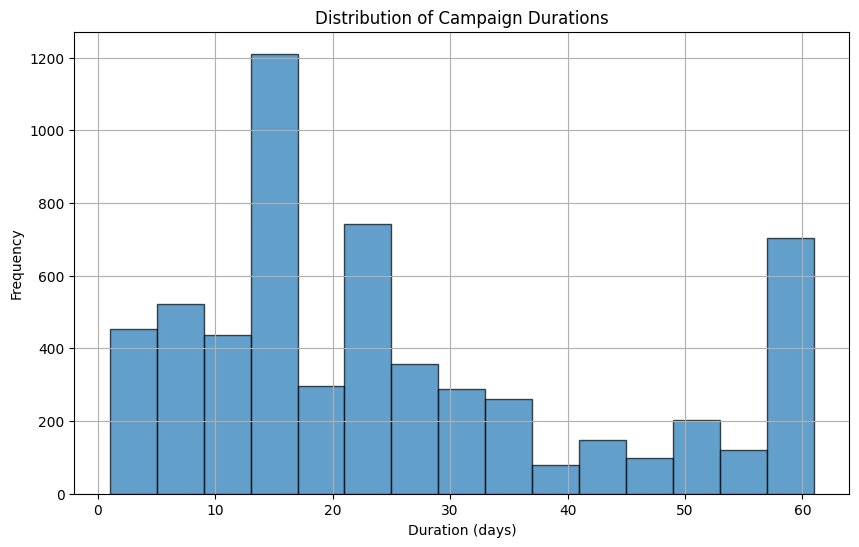

In [9]:
import matplotlib.pyplot as plt

# Print descriptive statistics for the 'duration' column
print("Descriptive Statistics for Campaign Durations:")
print(df['campaign_duration'].describe())

# Plot a histogram of the 'duration' column
plt.figure(figsize=(10, 6))
plt.hist(df['campaign_duration'], bins=15, edgecolor='k', alpha=0.7)
plt.title('Distribution of Campaign Durations')
plt.xlabel('Duration (days)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

In [126]:
import pandas as pd
df = pd.read_excel(r'data\interim\flights\all_flights.xlsx', dtype={'start_date': str, 'end_date': str})
df_mocks = df[df.mock_campaign == True]
df_no_mocks = df[df.mock_campaign == False]

print(len(df_no_mocks))
print(len(df_mocks))

5916
14358


Descriptive Statistics for Campaign Durations:
count    5916.000000
mean       25.033469
std        18.001209
min         1.000000
25%        13.000000
50%        21.000000
75%        35.000000
max        61.000000
Name: campaign_duration, dtype: float64


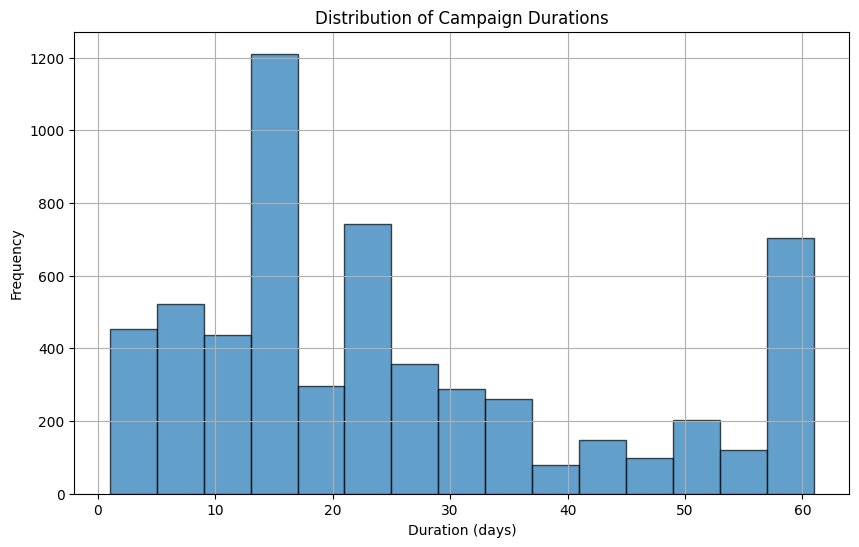

In [127]:
import matplotlib.pyplot as plt

# Print descriptive statistics for the 'duration' column
print("Descriptive Statistics for Campaign Durations:")
print(df_no_mocks['campaign_duration'].describe())

# Plot a histogram of the 'duration' column
plt.figure(figsize=(10, 6))
plt.hist(df_no_mocks['campaign_duration'], bins=15, edgecolor='k', alpha=0.7)
plt.title('Distribution of Campaign Durations')
plt.xlabel('Duration (days)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

Descriptive Statistics for Campaign Durations:
count    14358.000000
mean        13.483702
std         11.559777
min          1.000000
25%          5.000000
50%          9.000000
75%         20.000000
max         54.000000
Name: campaign_duration, dtype: float64


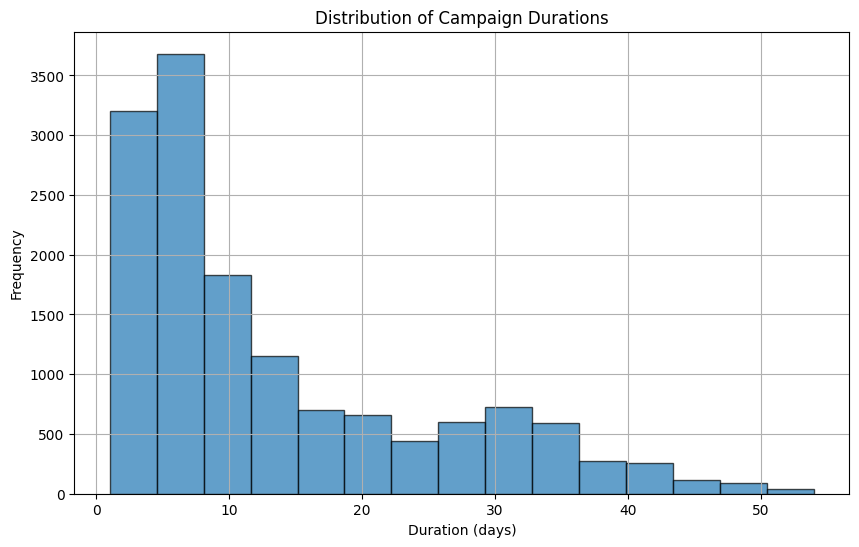

In [128]:
import matplotlib.pyplot as plt

# Print descriptive statistics for the 'duration' column
print("Descriptive Statistics for Campaign Durations:")
print(df_mocks['campaign_duration'].describe())

# Plot a histogram of the 'duration' column
plt.figure(figsize=(10, 6))
plt.hist(df_mocks['campaign_duration'], bins=15, edgecolor='k', alpha=0.7)
plt.title('Distribution of Campaign Durations')
plt.xlabel('Duration (days)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

Descriptive Statistics for Campaign Durations:
count    20274.000000
mean        16.853951
std         14.722334
min          1.000000
25%          6.000000
50%         12.000000
75%         25.000000
max         61.000000
Name: campaign_duration, dtype: float64


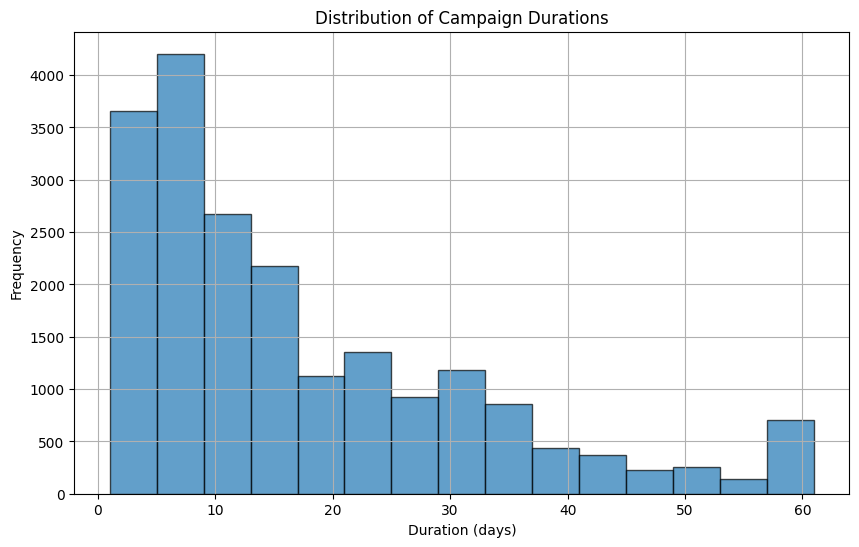

In [129]:
import matplotlib.pyplot as plt

# Print descriptive statistics for the 'duration' column
print("Descriptive Statistics for Campaign Durations:")
print(df['campaign_duration'].describe())

# Plot a histogram of the 'duration' column
plt.figure(figsize=(10, 6))
plt.hist(df['campaign_duration'], bins=15, edgecolor='k', alpha=0.7)
plt.title('Distribution of Campaign Durations')
plt.xlabel('Duration (days)')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


In [103]:
import datetime
import numpy as np

start_date = datetime.datetime(2022, 1, 1)
end_date = datetime.datetime(2022, 1, 14)
original_duration = (end_date - start_date).days + 1
print('original_duration:', original_duration)

min_mock_duration_ratio = 0.25
max_mock_duration_ratio= 0.9
max_allowed_overlap = 0.8
min_days_gap = 3

min_mock_duration = math.ceil(original_duration * min_mock_duration_ratio)
max_mock_duration = int(original_duration * max_mock_duration_ratio)

mock_duration = np.random.randint(min_mock_duration, max_mock_duration + 1)
print('mock duration:', mock_duration)

new_start_date = datetime.datetime(2022, 1, 1) + pd.DateOffset(days=np.random.randint(1, mock_duration + 1) - 1)
new_end_date = new_start_date + pd.DateOffset(days=mock_duration - 1)

print('new_start_date:', new_start_date)
print('new_end_date:', new_end_date)

start_date_gap = (new_start_date - start_date).days
end_date_gap = (end_date - new_end_date).days

print('start_date_gap:', start_date_gap)
print('end_date_gap:', end_date_gap)

if (new_start_date < start_date or new_end_date > end_date):
    print('wrong date')
    
if (start_date_gap < min_days_gap and end_date_gap < min_days_gap):
    print('too short gap')
    
overlap_days = max(0, (min(end_date, new_end_date) - max(start_date, new_start_date)).days + 1)
print('overlap_days:', overlap_days)
print(overlap_days / original_duration)
if (overlap_days / original_duration) > max_allowed_overlap:
    print('too much:', overlap_days / original_duration)

original_duration: 14
mock duration: 7
new_start_date: 2022-01-01 00:00:00
new_end_date: 2022-01-07 00:00:00
start_date_gap: 0
end_date_gap: 7
overlap_days: 7
0.5


In [6]:
start_date = '150124'
end_date = '170124'

def get_all_dates_in_range(start_date, end_date):
    return pd.date_range(start=start_date, end=end_date)

all_dates = get_all_dates_in_range(start_date, end_date)
all_dates

DatetimeIndex(['2024-01-15', '2024-01-16', '2024-01-17'], dtype='datetime64[ns]', freq='D')